# Module 1: Data Exploration, Wrangling, and Cleaning
## ● Inspection & Null Imputation
## ● Outlier Detection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("used_cars_data.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (7253, 14)


,S.No.,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74


In [2]:
# Dataset information
print("Dataset Information:")
df.info()

# Statistical summary
display(df.describe(include="all").T)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7253 entries, 0 to 7252
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   S.No.              7253 non-null   int64  
 1   Name               7253 non-null   str    
 2   Location           7253 non-null   str    
 3   Year               7253 non-null   int64  
 4   Kilometers_Driven  7253 non-null   int64  
 5   Fuel_Type          7253 non-null   str    
 6   Transmission       7253 non-null   str    
 7   Owner_Type         7253 non-null   str    
 8   Mileage            7251 non-null   str    
 9   Engine             7207 non-null   str    
 10  Power              7207 non-null   str    
 11  Seats              7200 non-null   float64
 12  New_Price          1006 non-null   str    
 13  Price              6019 non-null   float64
dtypes: float64(2), int64(3), str(9)
memory usage: 1.3 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
S.No.,7253.0,NaN,NaN,NaN,3626.0,2093.905084,0.0,1813.0,3626.0,5439.0,7252.0
Name,7253,2041,Mahindra XUV500 W8 2WD,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,7253,11,Mumbai,949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,7253.0,NaN,NaN,NaN,2013.365366,3.254421,1996.0,2011.0,2014.0,2016.0,2019.0
Kilometers_Driven,7253.0,NaN,NaN,NaN,58699.063146,84427.720583,171.0,34000.0,53416.0,73000.0,6500000.0
Fuel_Type,7253,5,Diesel,3852,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,7253,2,Manual,5204,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner_Type,7253,4,First,5952,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mileage,7251,450,17.0 kmpl,207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Engine,7207,150,1197 CC,732,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Missing values
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

missing = missing[missing["Missing_Count"] > 0].sort_values(
    by="Missing_Count",
    ascending=False
)

display(missing)

,Missing_Count,Missing_Percentage
New_Price,6247,86.129877
Price,1234,17.013650
Seats,53,0.730732
Engine,46,0.634220
Power,46,0.634220
Mileage,2,0.027575


In [4]:
# Columns containing numerical information stored as text
unit_columns = ["Mileage", "Engine", "Power", "New_Price"]

for col in unit_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.extract(r"([-+]?\d*\.?\d+)")[0],
        errors="coerce"
    )

print(df[unit_columns].dtypes)

Mileage      float64
Engine       float64
Power        float64
New_Price    float64
dtype: object


In [8]:
# Numerical columns
numeric_columns = df.select_dtypes(include="number").columns.tolist()

# Categorical columns
# Detect object columns directly without select_dtypes()
object_columns = df.columns[df.dtypes == "object"].tolist()

# Detect pandas string columns
string_columns = df.columns[df.dtypes == "string"].tolist()

# Combine categorical columns
categorical_columns = list(dict.fromkeys(object_columns + string_columns))

print("Numerical Columns:")
print(numeric_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['S.No.', 'Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats', 'New_Price', 'Price']

Categorical Columns:
['Name', 'Location', 'Fuel_Type', 'Transmission', 'Owner_Type']


In [9]:
# Numerical columns excluding the serial-number column
numeric_features = [
    col for col in numeric_columns
    if col != "S.No."
]

# Median imputation
for col in numeric_features:
    if df[col].isnull().sum() > 0:
        median_value = df[col].median()
        df[col] = df[col].fillna(median_value)

print("Missing numerical values after median imputation:")
print(df[numeric_features].isnull().sum())

Missing numerical values after median imputation:
Year                 0
Kilometers_Driven    0
Mileage              0
Engine               0
Power                0
Seats                0
New_Price            0
Price                0
dtype: int64


In [11]:
# Categorical columns
categorical_columns = df.columns[df.dtypes == "object"].tolist()

# Fill missing categorical values with the mode
for col in categorical_columns:
    if df[col].isnull().sum() > 0:
        mode_value = df[col].mode()[0]
        df[col] = df[col].fillna(mode_value)

print("Missing categorical values:")
print(df[categorical_columns].isnull().sum())

Missing categorical values:
Series([], dtype: float64)


In [12]:
print("Total missing values after cleaning:")
print(df.isnull().sum().sum())

Total missing values after cleaning:
0


In [13]:
def detect_outliers_iqr(data, columns):
    outlier_summary = []

    for col in columns:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = data[
            (data[col] < lower_bound) |
            (data[col] > upper_bound)
        ]

        outlier_summary.append({
            "Column": col,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "Lower_Bound": lower_bound,
            "Upper_Bound": upper_bound,
            "Outlier_Count": len(outliers)
        })

    return pd.DataFrame(outlier_summary)

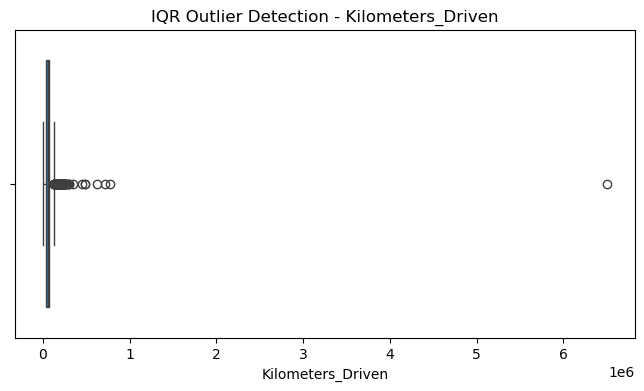

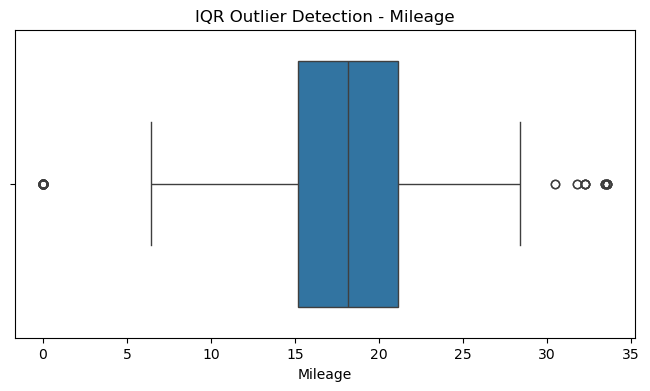

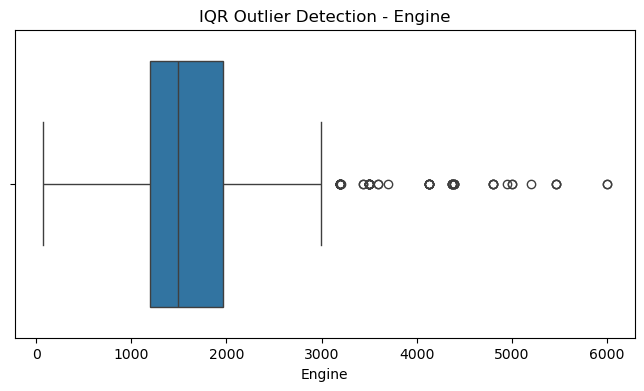

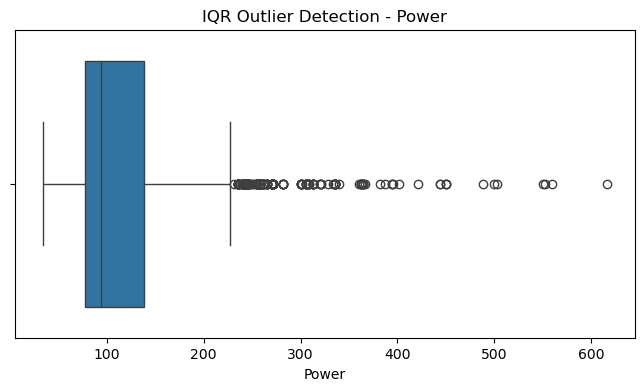

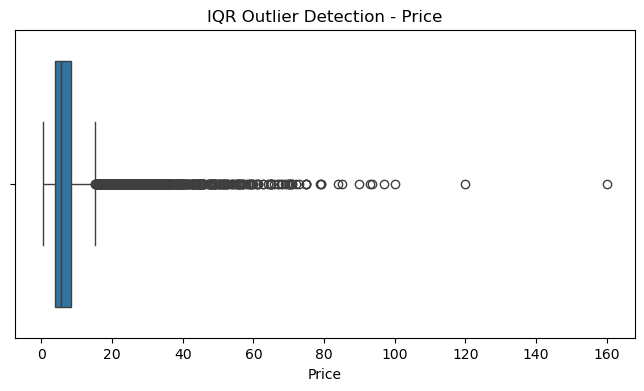

In [14]:
important_numeric = [
    "Kilometers_Driven",
    "Mileage",
    "Engine",
    "Power",
    "Price"
]

for col in important_numeric:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f"IQR Outlier Detection - {col}")
    plt.xlabel(col)
    plt.show()

In [15]:
clean_df = df.copy()

outlier_columns = [
    "Kilometers_Driven",
    "Mileage",
    "Engine",
    "Power",
    "Price"
]

for col in outlier_columns:

    Q1 = clean_df[col].quantile(0.25)
    Q3 = clean_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    clean_df = clean_df[
        (clean_df[col] >= lower_bound) &
        (clean_df[col] <= upper_bound)
    ]

print("Original rows:", len(df))
print("Cleaned rows:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))

Original rows: 7253
Cleaned rows: 5820
Rows removed: 1433


In [16]:
print("Final Dataset Shape:", clean_df.shape)

print("\nMissing Values:")
print(clean_df.isnull().sum())

print("\nDuplicate Rows:")
print(clean_df.duplicated().sum())

print("\nFinal Data Types:")
print(clean_df.dtypes)

Final Dataset Shape: (5820, 14)

Missing Values:
S.No.                0
Name                 0
Location             0
Year                 0
Kilometers_Driven    0
Fuel_Type            0
Transmission         0
Owner_Type           0
Mileage              0
Engine               0
Power                0
Seats                0
New_Price            0
Price                0
dtype: int64

Duplicate Rows:
0

Final Data Types:
S.No.                  int64
Name                     str
Location                 str
Year                   int64
Kilometers_Driven      int64
Fuel_Type                str
Transmission             str
Owner_Type               str
Mileage              float64
Engine               float64
Power                float64
Seats                float64
New_Price            float64
Price                float64
dtype: object


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================================
# MODULE 1: DATA EXPLORATION, WRANGLING AND CLEANING
# ==========================================================

# 1. Load dataset
df = pd.read_csv("used_cars_data.csv")

print("Original Dataset Shape:", df.shape)

# ----------------------------------------------------------
# 2. Data Exploration
# ----------------------------------------------------------

print("\n===== DATA INFORMATION =====")
df.info()

print("\n===== FIRST 5 ROWS =====")
print(df.head())

print("\n===== DUPLICATES =====")
print("Duplicate rows:", df.duplicated().sum())

print("\n===== MISSING VALUES =====")
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().sum() / len(df) * 100
})

print(missing[missing["Missing_Count"] > 0]
      .sort_values("Missing_Count", ascending=False))


# ----------------------------------------------------------
# 3. Convert Unit-Based Columns to Numeric
# ----------------------------------------------------------

unit_columns = [
    "Mileage",
    "Engine",
    "Power",
    "New_Price"
]

for col in unit_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str)
          .str.extract(r"([-+]?\d*\.?\d+)")[0],
        errors="coerce"
    )


# ----------------------------------------------------------
# 4. Identify Numerical and Categorical Columns
# ----------------------------------------------------------

numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print("\nNumerical Columns:")
print(numeric_columns)

# Categorical columns
categorical_columns = df.columns[df.dtypes == "object"].tolist()

# Fill missing categorical values with mode
for col in categorical_columns:
    if df[col].isnull().sum() > 0:
        mode_value = df[col].mode()[0]
        df[col] = df[col].fillna(mode_value)

print("Missing categorical values:")
print(df[categorical_columns].isnull().sum())



# ----------------------------------------------------------
# 5. Remove Rows with Missing Target Price
# ----------------------------------------------------------

# Price is the prediction target.
# Missing target values should not be median-imputed.

df = df.dropna(subset=["Price"])


# ----------------------------------------------------------
# 6. Median Imputation for Numerical Features
# ----------------------------------------------------------

numeric_features = [
    col for col in numeric_columns
    if col not in ["S.No.", "Price"]
]

for col in numeric_features:

    if df[col].isnull().sum() > 0:

        median_value = df[col].median()

        df[col] = df[col].fillna(median_value)


# ----------------------------------------------------------
# 7. Mode Imputation for Categorical Features
# ----------------------------------------------------------

for col in categorical_columns:

    if df[col].isnull().sum() > 0:

        mode_value = df[col].mode()[0]

        df[col] = df[col].fillna(mode_value)


# ----------------------------------------------------------
# 8. Verify Missing Values
# ----------------------------------------------------------

print("\n===== AFTER IMPUTATION =====")
print(df.isnull().sum())


# ----------------------------------------------------------
# 9. IQR Outlier Detection
# ----------------------------------------------------------

outlier_columns = [
    "Kilometers_Driven",
    "Mileage",
    "Engine",
    "Power",
    "Price"
]

outlier_summary = []

for col in outlier_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Column": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_count
    })

outlier_df = pd.DataFrame(outlier_summary)

print("\n===== IQR OUTLIER SUMMARY =====")
print(outlier_df)


# ----------------------------------------------------------
# 10. Remove Extreme Outliers
# ----------------------------------------------------------

clean_df = df.copy()

for col in outlier_columns:

    Q1 = clean_df[col].quantile(0.25)
    Q3 = clean_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    clean_df = clean_df[
        (clean_df[col] >= lower_bound) &
        (clean_df[col] <= upper_bound)
    ]


# ----------------------------------------------------------
# 11. Final Validation
# ----------------------------------------------------------

print("\n===== FINAL RESULTS =====")

print("Original rows:", 7253)
print("Rows after removing missing Price:", len(df))
print("Final cleaned rows:", len(clean_df))
print("Rows removed as outliers:", len(df) - len(clean_df))

print("\nFinal missing values:")
print(clean_df.isnull().sum())

print("\nFinal duplicate rows:")
print(clean_df.duplicated().sum())


# ----------------------------------------------------------
# 12. Save Clean Dataset
# ----------------------------------------------------------

clean_df.to_csv(
    "used_cars_data_cleaned.csv",
    index=False
)

print("\nClean dataset saved as:")
print("used_cars_data_cleaned.csv")

Original Dataset Shape: (7253, 14)

===== DATA INFORMATION =====
<class 'pandas.DataFrame'>
RangeIndex: 7253 entries, 0 to 7252
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   S.No.              7253 non-null   int64  
 1   Name               7253 non-null   str    
 2   Location           7253 non-null   str    
 3   Year               7253 non-null   int64  
 4   Kilometers_Driven  7253 non-null   int64  
 5   Fuel_Type          7253 non-null   str    
 6   Transmission       7253 non-null   str    
 7   Owner_Type         7253 non-null   str    
 8   Mileage            7251 non-null   str    
 9   Engine             7207 non-null   str    
 10  Power              7207 non-null   str    
 11  Seats              7200 non-null   float64
 12  New_Price          1006 non-null   str    
 13  Price              6019 non-null   float64
dtypes: float64(2), int64(3), str(9)
memory usage: 1.3 MB

===== FIRST 

# Module 2: Feature Engineering, Encoding, and Scaling 
### ● Categorical Encoding
### ● Feature Scaling

In [19]:
# ============================================================
# MODULE 2: FEATURE ENGINEERING, ENCODING & SCALING
# Dataset: used_cars_data.csv
# ============================================================

import pandas as pd
import numpy as np

from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ------------------------------------------------------------
# 1. Load Dataset
# ------------------------------------------------------------

df = pd.read_csv("used_cars_data.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# Make a copy so the original dataset remains unchanged
df_encoded = df.copy()


# ------------------------------------------------------------
# 2. Convert Object/Numeric Columns
# ------------------------------------------------------------

# Remove units such as "km/kg", "bhp", "CC", "Lakh"
def extract_numeric(series):
    return pd.to_numeric(
        series.astype(str).str.extract(r'([\d.]+)')[0],
        errors='coerce'
    )

# Convert columns containing units to numerical values
for col in ["Mileage", "Engine", "Power", "New_Price"]:
    if col in df_encoded.columns:
        df_encoded[col] = extract_numeric(df_encoded[col])


# ------------------------------------------------------------
# 3. Feature Engineering
# ------------------------------------------------------------

# Price Efficiency Index
# Lower value = lower price relative to kilometers driven
# A small constant prevents division by zero.

df_encoded["Price_Per_KM"] = (
    df_encoded["Price"] /
    (df_encoded["Kilometers_Driven"] + 1)
)

# More interpretable version:
df_encoded["Price_Per_1000_KM"] = (
    df_encoded["Price"] /
    (df_encoded["Kilometers_Driven"] + 1)
) * 1000

# Vehicle Age
current_year = 2026

df_encoded["Vehicle_Age"] = (
    current_year - df_encoded["Year"]
)

print("\nNew Feature Columns:")
print([
    "Price_Per_KM",
    "Price_Per_1000_KM",
    "Vehicle_Age"
])


# ------------------------------------------------------------
# 4. Identify Categorical Variables
# ------------------------------------------------------------

categorical_columns = [
    "Fuel_Type",
    "Transmission",
    "Owner_Type",
    "Location"
]

# Keep only columns that actually exist
categorical_columns = [
    col for col in categorical_columns
    if col in df_encoded.columns
]

print("\nCategorical Columns:")
print(categorical_columns)


# ------------------------------------------------------------
# 5. One-Hot Encoding
# ------------------------------------------------------------

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoded_array = encoder.fit_transform(
    df_encoded[categorical_columns].fillna("Unknown")
)

encoded_columns = encoder.get_feature_names_out(
    categorical_columns
)

encoded_df = pd.DataFrame(
    encoded_array,
    columns=encoded_columns,
    index=df_encoded.index
)

# Remove original categorical columns
df_encoded = df_encoded.drop(
    columns=categorical_columns
)

# Add encoded columns
df_encoded = pd.concat(
    [df_encoded, encoded_df],
    axis=1
)

print("\nAfter One-Hot Encoding:")
print(df_encoded.shape)


# ------------------------------------------------------------
# 6. Handle Missing Numerical Values
# ------------------------------------------------------------

numeric_columns = df_encoded.select_dtypes(
    include=np.number
).columns

for col in numeric_columns:
    df_encoded[col] = df_encoded[col].fillna(
        df_encoded[col].median()
    )


# ------------------------------------------------------------
# 7. Feature Scaling using StandardScaler
# ------------------------------------------------------------

scaler = StandardScaler()

# Do not scale S.No. because it is an identifier
scaling_columns = [
    col for col in numeric_columns
    if col != "S.No."
]

df_encoded[scaling_columns] = scaler.fit_transform(
    df_encoded[scaling_columns]
)


# ------------------------------------------------------------
# 8. Final Dataset Inspection
# ------------------------------------------------------------

print("\nFinal Dataset Shape:")
print(df_encoded.shape)

print("\nFirst 5 Rows:")
print(df_encoded.head())

print("\nMean of Scaled Features:")
print(df_encoded[scaling_columns].mean().round(3))

print("\nStandard Deviation of Scaled Features:")
print(df_encoded[scaling_columns].std().round(3))

Dataset Shape: (7253, 14)

Columns:
['S.No.', 'Name', 'Location', 'Year', 'Kilometers_Driven', 'Fuel_Type', 'Transmission', 'Owner_Type', 'Mileage', 'Engine', 'Power', 'Seats', 'New_Price', 'Price']

New Feature Columns:
['Price_Per_KM', 'Price_Per_1000_KM', 'Vehicle_Age']

Categorical Columns:
['Fuel_Type', 'Transmission', 'Owner_Type', 'Location']

After One-Hot Encoding:
(7253, 35)

Final Dataset Shape:
(7253, 35)

First 5 Rows:
   S.No.                              Name      Year  Kilometers_Driven  \
0      0            Maruti Wagon R LXI CNG -1.034162           0.157553   
1      1  Hyundai Creta 1.6 CRDi SX Option  0.502316          -0.209650   
2      2                      Honda Jazz V -0.726866          -0.150424   
3      3                 Maruti Ertiga VDI -0.419571           0.335232   
4      4   Audi A4 New 2.0 TDI Multitronic -0.112275          -0.213559   

    Mileage    Engine     Power     Seats  New_Price     Price  ...  \
0  1.854406 -1.041041 -1.023310 -0.343243 

# Module 3: Feature Selection and Validation Setup 
### ● Feature Selection
### ● Validation Strategy 

In [23]:
# ============================================
# MODULE 3: FEATURE SELECTION & VALIDATION
# ============================================

import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestRegressor

# --------------------------------------------
# 1. Load Dataset
# --------------------------------------------

df = pd.read_csv("used_cars_data.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())


# --------------------------------------------
# 2. Remove rows where target Price is missing
# --------------------------------------------

df = df.dropna(subset=["Price"]).copy()

# --------------------------------------------
# 3. Convert text-based numerical columns
# --------------------------------------------

def extract_number(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    # Handle null/empty values
    if value.lower() in ['null', 'nan', 'none', '', '-', '--']:
        return np.nan

    try:
        return float(value.split('@')[0].strip())
    except (ValueError, TypeError):
        return np.nan

# --------------------------------------------
# 4. Remove unnecessary ID column
# --------------------------------------------

df = df.drop(columns=["S.No."], errors="ignore")


# --------------------------------------------
# 5. Separate Features and Target
# --------------------------------------------

X = df.drop(columns=["Price"])
y = df["Price"]

print("\nFeatures:", X.shape)
print("Target:", y.shape)


# --------------------------------------------
# 6. Identify Numerical and Categorical Columns
# --------------------------------------------

# Identify numerical features
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

# Identify categorical features
categorical_features = X.columns[
    X.dtypes == 'object'
].tolist()

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


# --------------------------------------------
# 7. Preprocessing
# --------------------------------------------

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


# --------------------------------------------
# 8. Transform Data
# --------------------------------------------

X_processed = preprocessor.fit_transform(X)

feature_names = preprocessor.get_feature_names_out()

X_processed = pd.DataFrame(
    X_processed,
    columns=feature_names,
    index=X.index
)

print("\nProcessed Feature Shape:", X_processed.shape)


# ============================================
# 9. RFE FEATURE SELECTION
# ============================================

# Random Forest is used as the wrapper estimator
estimator = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Select approximately 50% of the features
n_features_to_select = max(
    1,
    X_processed.shape[1] // 2
)

rfe = RFE(
    estimator=estimator,
    n_features_to_select=n_features_to_select,
    step=0.1
)

rfe.fit(X_processed, y)


# --------------------------------------------
# 10. Selected Features
# --------------------------------------------

selected_features = X_processed.columns[rfe.support_]

print("\n===================================")
print("RFE FEATURE SELECTION RESULTS")
print("===================================")

print("Original Features:", X_processed.shape[1])
print("Selected Features:", len(selected_features))

print("\nSelected Features:")
for feature in selected_features:
    print(feature)


# --------------------------------------------
# 11. Create Reduced Dataset
# --------------------------------------------

X_selected = X_processed[selected_features]

print("\nReduced Dataset Shape:")
print(X_selected.shape)


# ============================================
# 12. STRATIFIED K-FOLD VALIDATION
# ============================================

# StratifiedKFold requires discrete classes.
# For regression, divide Price into quantile bins.

price_bins = pd.qcut(
    y,
    q=5,
    labels=False,
    duplicates="drop"
)

print("\nPrice Bin Distribution:")
print(price_bins.value_counts().sort_index())


# --------------------------------------------
# 13. Create Stratified K-Fold
# --------------------------------------------

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# --------------------------------------------
# 14. Display Fold Distribution
# --------------------------------------------

print("\n===================================")
print("STRATIFIED K-FOLD VALIDATION")
print("===================================")

for fold, (train_index, validation_index) in enumerate(
    skf.split(X_selected, price_bins),
    start=1
):

    X_train = X_selected.iloc[train_index]
    X_validation = X_selected.iloc[validation_index]

    y_train = y.iloc[train_index]
    y_validation = y.iloc[validation_index]

    print(f"\nFold {fold}")
    print("----------------------")
    print("Training samples:", len(train_index))
    print("Validation samples:", len(validation_index))
    print("Training Price Mean:", round(y_train.mean(), 2))
    print("Validation Price Mean:", round(y_validation.mean(), 2))


print("\nModule 3 completed successfully.")

Dataset Shape: (7253, 14)

Columns:
['S.No.', 'Name', 'Location', 'Year', 'Kilometers_Driven', 'Fuel_Type', 'Transmission', 'Owner_Type', 'Mileage', 'Engine', 'Power', 'Seats', 'New_Price', 'Price']

Features: (6019, 12)
Target: (6019,)

Numerical Features:
['Year', 'Kilometers_Driven', 'Seats']

Categorical Features:
[]

Processed Feature Shape: (6019, 3)

RFE FEATURE SELECTION RESULTS
Original Features: 3
Selected Features: 1

Selected Features:
num__Kilometers_Driven

Reduced Dataset Shape:
(6019, 1)

Price Bin Distribution:
Price
0    1211
1    1211
2    1222
3    1192
4    1183
Name: count, dtype: int64

STRATIFIED K-FOLD VALIDATION

Fold 1
----------------------
Training samples: 4815
Validation samples: 1204
Training Price Mean: 9.41
Validation Price Mean: 9.76

Fold 2
----------------------
Training samples: 4815
Validation samples: 1204
Training Price Mean: 9.38
Validation Price Mean: 9.86

Fold 3
----------------------
Training samples: 4815
Validation samples: 1204
Training 

# Module 4: Model Tuning and Baseline Algorithms 
### ● Hyperparameter Search
### ● Baseline Modeling

In [24]:
# ============================================================
# MODULE 4: MODEL TUNING AND BASELINE ALGORITHMS
# Dataset: watch_listings_clean.csv
# Target: price_band
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")


# ============================================================
# 1. LOAD DATA
# ============================================================

df = pd.read_csv("watch_listings_clean.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())


# ============================================================
# 2. DEFINE TARGET
# ============================================================

# Target variable
target = "price_band"

X = df.drop(columns=[target])
y = df[target]

print("\nTarget Distribution:")
print(y.value_counts())


# ============================================================
# 3. REMOVE DATA LEAKAGE / IDENTIFIER COLUMNS
# ============================================================

# price_aed and price_usd_approx directly determine price_band.
# They must NOT be used as predictors.

columns_to_drop = [
    "listing_id",
    "reference",
    "price_aed",
    "price_usd_approx",
    "scraped_date",
    "source"
]

X = X.drop(
    columns=[c for c in columns_to_drop if c in X.columns]
)

print("\nFeatures after removing leakage/ID columns:")
print(X.columns.tolist())


# ============================================================
# 4. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ============================================================

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


# ============================================================
# 5. PREPROCESSING PIPELINE
# ============================================================

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)


# ============================================================
# 6. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


# ============================================================
# 7. STRATIFIED K-FOLD VALIDATION
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("\nStratified 5-Fold Cross-Validation configured.")


# ============================================================
# 8. BASELINE MODEL 1 — LOGISTIC REGRESSION
# ============================================================

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)


# ============================================================
# 9. BASELINE MODEL 2 — KNN
# ============================================================

knn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            KNeighborsClassifier(
                n_neighbors=5
            )
        )
    ]
)


# ============================================================
# 10. BASELINE MODEL 3 — SVM
# ============================================================

svm_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            SVC(
                kernel="rbf",
                probability=True,
                random_state=42
            )
        )
    ]
)


# ============================================================
# 11. FUNCTION FOR BASELINE EVALUATION
# ============================================================

def evaluate_model(model, model_name):

    scoring = {
        "accuracy": "accuracy",
        "precision": "precision_weighted",
        "recall": "recall_weighted",
        "f1": "f1_weighted"
    }

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    return {
        "Model": model_name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean()
    }


# ============================================================
# 12. TRAIN BASELINE MODELS
# ============================================================

baseline_results = []

baseline_results.append(
    evaluate_model(
        logistic_model,
        "Logistic Regression"
    )
)

baseline_results.append(
    evaluate_model(
        knn_model,
        "KNN"
    )
)

baseline_results.append(
    evaluate_model(
        svm_model,
        "SVM"
    )
)


# ============================================================
# 13. DISPLAY BASELINE RESULTS
# ============================================================

baseline_df = pd.DataFrame(baseline_results)

print("\n==============================================")
print("BASELINE MODEL RESULTS")
print("==============================================")

print(
    baseline_df.round(4).to_string(index=False)
)


# ============================================================
# 14. RANDOM FOREST + RANDOMIZED SEARCH
# ============================================================

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)


# ============================================================
# 15. HYPERPARAMETER SEARCH SPACE
# ============================================================

param_distributions = {
    "classifier__n_estimators": [
        100,
        200,
        300,
        500,
        800
    ],

    "classifier__max_depth": [
        None,
        5,
        10,
        15,
        20,
        30
    ],

    "classifier__min_samples_split": [
        2,
        5,
        10,
        15
    ],

    "classifier__min_samples_leaf": [
        1,
        2,
        4,
        8
    ],

    "classifier__max_features": [
        "sqrt",
        "log2",
        None
    ],

    "classifier__bootstrap": [
        True,
        False
    ]
}


# ============================================================
# 16. RANDOMIZED SEARCH
# ============================================================

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=25,
    scoring="f1_weighted",
    cv=cv,
    verbose=1,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

print("\n==============================================")
print("STARTING RANDOMIZED SEARCH")
print("==============================================")

random_search.fit(
    X_train,
    y_train
)


# ============================================================
# 17. BEST HYPERPARAMETERS
# ============================================================

print("\n==============================================")
print("BEST RANDOM FOREST PARAMETERS")
print("==============================================")

print(random_search.best_params_)

print(
    "\nBest Cross-Validation F1 Score:",
    round(random_search.best_score_, 4)
)


# ============================================================
# 18. BEST RANDOM FOREST MODEL
# ============================================================

best_rf = random_search.best_estimator_


# ============================================================
# 19. TEST SET EVALUATION
# ============================================================

models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "SVM": svm_model,
    "Tuned Random Forest": best_rf
}

test_results = []

for name, model in models.items():

    print("\n==============================================")
    print(name)
    print("==============================================")

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(X_test)

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    test_results.append({
        "Model": name,
        "Test Accuracy": accuracy,
        "Test Precision": precision,
        "Test Recall": recall,
        "Test F1": f1
    })

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            predictions,
            zero_division=0
        )
    )

    print("Confusion Matrix:")
    print(
        confusion_matrix(
            y_test,
            predictions
        )
    )


# ============================================================
# 20. FINAL MODEL COMPARISON
# ============================================================

test_results_df = pd.DataFrame(test_results)

print("\n==============================================")
print("FINAL MODEL COMPARISON")
print("==============================================")

print(
    test_results_df
    .round(4)
    .sort_values(
        by="Test F1",
        ascending=False
    )
    .to_string(index=False)
)


# ============================================================
# 21. SAVE RESULTS
# ============================================================

baseline_df.to_csv(
    "module4_baseline_results.csv",
    index=False
)

test_results_df.to_csv(
    "module4_final_model_results.csv",
    index=False
)

print("\nResults saved:")
print("1. module4_baseline_results.csv")
print("2. module4_final_model_results.csv")

Dataset Shape: (515, 17)

Columns:
['listing_id', 'brand', 'brand_tier', 'model', 'reference', 'year', 'watch_age_years', 'age_category', 'condition', 'price_aed', 'price_usd_approx', 'price_band', 'seller_type', 'is_dealer', 'location', 'scraped_date', 'source']

Target Distribution:
price_band
Entry (<10K)            165
Mid (10K-30K)           162
Luxury (75K-200K)        73
Premium (30K-75K)        70
Ultra Luxury (200K+)     45
Name: count, dtype: int64

Features after removing leakage/ID columns:
['brand', 'brand_tier', 'model', 'year', 'watch_age_years', 'age_category', 'condition', 'seller_type', 'is_dealer', 'location']

Numerical Features:
['year', 'watch_age_years', 'is_dealer']

Categorical Features:
['brand', 'brand_tier', 'model', 'age_category', 'condition', 'seller_type', 'location']

Training samples: 412
Testing samples: 103

Stratified 5-Fold Cross-Validation configured.

BASELINE MODEL RESULTS
              Model  CV Accuracy  CV Precision  CV Recall  CV F1
Logistic

# Module 5: Ensemble Learning and Final Evaluation 
### ● Ensemble Architectures
### ● Model Comparison

In [25]:
import pandas as pd
import numpy as np

from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ============================================================
# 1. LOAD DATA
# ============================================================

df = pd.read_csv("used_cars_data.csv")

print("Dataset Shape:", df.shape)
print(df.head())


# ============================================================
# 2. CLEAN NUMERIC COLUMNS
# ============================================================

def extract_number(series):
    return pd.to_numeric(
        series.astype(str).str.extract(r'([-+]?\d*\.?\d+)')[0],
        errors='coerce'
    )


for col in ["Mileage", "Engine", "Power", "New_Price"]:
    df[col] = extract_number(df[col])


# Remove rows where target is missing
df = df.dropna(subset=["Price"]).reset_index(drop=True)


# ============================================================
# 3. DEFINE FEATURES AND TARGET
# ============================================================

# Price = target variable
y = df["Price"]

# Remove target, serial number and high-cardinality car name
X = df.drop(
    columns=["Price", "S.No.", "Name"],
    errors="ignore"
)

print("\nX Shape:", X.shape)
print("Target Shape:", y.shape)


# ============================================================
# 4. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ============================================================

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


# ============================================================
# 5. PREPROCESSING PIPELINE
# ============================================================

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


# ============================================================
# 6. DEFINE MODELS
# ============================================================

models = {

    # Baseline Models
    "Linear Regression": LinearRegression(),

    "KNN": KNeighborsRegressor(
        n_neighbors=7,
        weights="distance"
    ),

    "SVR": SVR(
        C=10,
        epsilon=0.1,
        kernel="rbf"
    ),

    # Ensemble 1: Bagging
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ),

    # Ensemble 2: Boosting
    "AdaBoost": AdaBoostRegressor(
        estimator=DecisionTreeRegressor(
            max_depth=4,
            random_state=42
        ),
        n_estimators=150,
        learning_rate=0.05,
        random_state=42
    )
}


# ============================================================
# 7. CROSS-VALIDATION
# ============================================================

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}


# ============================================================
# 8. TRAIN AND COMPARE ALL MODELS
# ============================================================

results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    results.append({
        "Model": name,
        "CV MAE": -scores["test_MAE"].mean(),
        "CV RMSE": -scores["test_RMSE"].mean(),
        "CV R2": scores["test_R2"].mean(),
        "R2 Std": scores["test_R2"].std()
    })


# ============================================================
# 9. MODEL COMPARISON
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="CV RMSE",
    ascending=True
)

print("\n========================================")
print("MODEL COMPARISON")
print("========================================")

print(results_df.to_string(index=False))


# ============================================================
# 10. FINAL TRAIN-TEST EVALUATION
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

final_results = []

for name in ["Random Forest", "AdaBoost"]:

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", models[name])
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    final_results.append({
        "Model": name,
        "Test MAE": mae,
        "Test RMSE": rmse,
        "Test R2": r2
    })


final_results_df = pd.DataFrame(final_results)

print("\n========================================")
print("FINAL TEST PERFORMANCE")
print("========================================")

print(final_results_df.to_string(index=False))


# ============================================================
# 11. DEPLOYMENT RECOMMENDATION
# ============================================================

best_model = results_df.iloc[0]["Model"]

print("\n========================================")
print("DEPLOYMENT RECOMMENDATION")
print("========================================")

print(
    f"Based on 5-fold cross-validation, "
    f"{best_model} provides the strongest overall "
    f"predictive performance."
)

Dataset Shape: (7253, 14)
   S.No.                              Name    Location  Year  \
0      0            Maruti Wagon R LXI CNG      Mumbai  2010   
1      1  Hyundai Creta 1.6 CRDi SX Option        Pune  2015   
2      2                      Honda Jazz V     Chennai  2011   
3      3                 Maruti Ertiga VDI     Chennai  2012   
4      4   Audi A4 New 2.0 TDI Multitronic  Coimbatore  2013   

   Kilometers_Driven Fuel_Type Transmission Owner_Type     Mileage   Engine  \
0              72000       CNG       Manual      First  26.6 km/kg   998 CC   
1              41000    Diesel       Manual      First  19.67 kmpl  1582 CC   
2              46000    Petrol       Manual      First   18.2 kmpl  1199 CC   
3              87000    Diesel       Manual      First  20.77 kmpl  1248 CC   
4              40670    Diesel    Automatic     Second   15.2 kmpl  1968 CC   

       Power  Seats  New_Price  Price  
0  58.16 bhp    5.0        NaN   1.75  
1  126.2 bhp    5.0        NaN  12